# Load Required Libraries
Import necessary libraries such as pandas, numpy, matplotlib, and seaborn.

In [10]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Load and Inspect Dataset
Load the data.csv file into a pandas DataFrame and inspect its structure, including columns, data types, and missing values.

In [11]:
# Load the dataset
data_path = './data/data.csv'
df = pd.read_csv(data_path)

# Display the first few rows of the dataset
df.head()

,acousticness,artists,danceability,duration_ms,energy,explicit,id,instrumentalness,key,liveness,loudness,mode,name,popularity,release_date,speechiness,tempo,valence,year
0,0.995,['Carl Woitschach'],0.708,158648,0.1950,0,6KbQ3uYMLKb5jDxLF7wYDD,0.563,10,0.1510,-12.428,1,Singende Bataillone 1. Teil,0,1928,0.0506,118.469,0.7790,1928
1,0.994,"['Robert Schumann', 'Vladimir Horowitz']",0.379,282133,0.0135,0,6KuQTIu1KoTTkLXKrwlLPV,0.901,8,0.0763,-28.454,1,"Fantasiestücke, Op. 111: Più tosto lento",0,1928,0.0462,83.972,0.0767,1928
2,0.604,['Seweryn Goszczyński'],0.749,104300,0.2200,0,6L63VW0PibdM1HDSBoqnoM,0.000,5,0.1190,-19.924,0,Chapter 1.18 - Zamek kaniowski,0,1928,0.9290,107.177,0.8800,1928
3,0.995,['Francisco Canaro'],0.781,180760,0.1300,0,6M94FkXd15sOAOQYRnWPN8,0.887,1,0.1110,-14.734,0,Bebamos Juntos - Instrumental (Remasterizado),0,1928-09-25,0.0926,108.003,0.7200,1928
4,0.990,"['Frédéric Chopin', 'Vladimir Horowitz']",0.210,687733,0.2040,0,6N6tiFZ9vLTSOIxkj8qKrd,0.908,11,0.0980,-16.829,1,"Polonaise-Fantaisie in A-Flat Major, Op. 61",1,1928,0.0424,62.149,0.0693,1928


In [12]:
# Inspect the structure of the dataset
df.info()

# Check for missing values
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 169909 entries, 0 to 169908
Data columns (total 19 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   acousticness      169909 non-null  float64
 1   artists           169909 non-null  object 
 2   danceability      169909 non-null  float64
 3   duration_ms       169909 non-null  int64  
 4   energy            169909 non-null  float64
 5   explicit          169909 non-null  int64  
 6   id                169909 non-null  object 
 7   instrumentalness  169909 non-null  float64
 8   key               169909 non-null  int64  
 9   liveness          169909 non-null  float64
 10  loudness          169909 non-null  float64
 11  mode              169909 non-null  int64  
 12  name              169909 non-null  object 
 13  popularity        169909 non-null  int64  
 14  release_date      169909 non-null  object 
 15  speechiness       169909 non-null  float64
 16  tempo             16

acousticness        0
artists             0
danceability        0
duration_ms         0
energy              0
explicit            0
id                  0
instrumentalness    0
key                 0
liveness            0
loudness            0
mode                0
name                0
popularity          0
release_date        0
speechiness         0
tempo               0
valence             0
year                0
dtype: int64

# Data Cleaning and Preprocessing
Handle missing values, rename columns for clarity, and ensure data types are appropriate for analysis.

In [13]:
# Rename columns for clarity
df.rename(columns={
    'acousticness': 'Acousticness',
    'artists': 'Artists',
    'danceability': 'Danceability',
    'duration_ms': 'Duration_ms',
    'energy': 'Energy',
    'explicit': 'Explicit',
    'id': 'Track_ID',
    'instrumentalness': 'Instrumentalness',
    'key': 'Key',
    'liveness': 'Liveness',
    'loudness': 'Loudness',
    'mode': 'Mode',
    'name': 'Track_Name',
    'popularity': 'Popularity',
    'release_date': 'Release_Date',
    'speechiness': 'Speechiness',
    'tempo': 'Tempo',
    'valence': 'Valence',
    'year': 'Year'
}, inplace=True)

# Handle missing values
df.fillna(0, inplace=True)

# Ensure data types are appropriate
df['Release_Date'] = pd.to_datetime(df['Release_Date'], errors='coerce')

# Descriptive Statistics
Generate summary statistics for numerical and categorical columns to understand the dataset's distribution.

In [14]:
# Generate summary statistics for numerical columns
df.describe()

# Generate summary statistics for categorical columns
df.describe(include=['object'])

,Artists,Track_ID,Track_Name
count,169909,169909,169909
unique,33375,169909,132940
top,['Эрнест Хемингуэй'],6KbQ3uYMLKb5jDxLF7wYDD,Summertime
freq,1215,1,62


# Data Visualization

In this section, we will create visualizations to better understand the data and uncover patterns related to the business KPIs. The visualizations will include:

1. Distribution of song popularity.
2. Top-performing artists based on song streams.
3. User engagement metrics over time.
4. Correlation heatmap for numerical features.

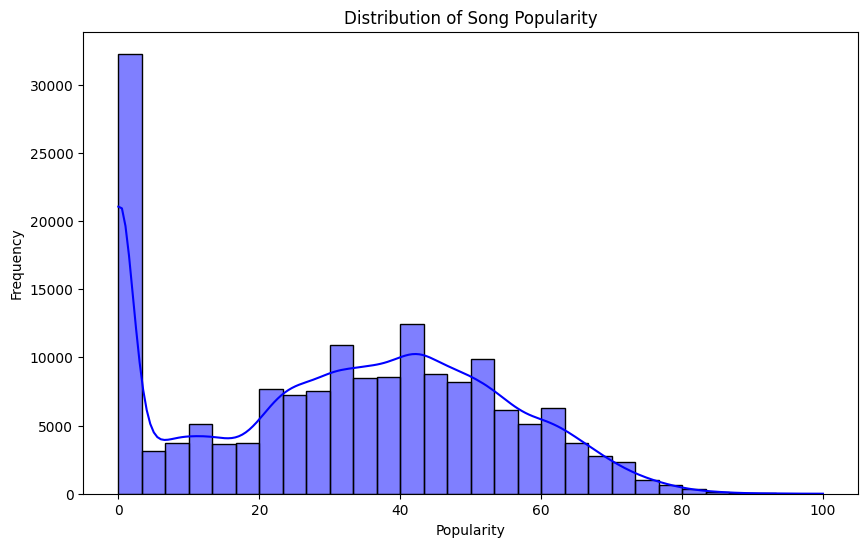

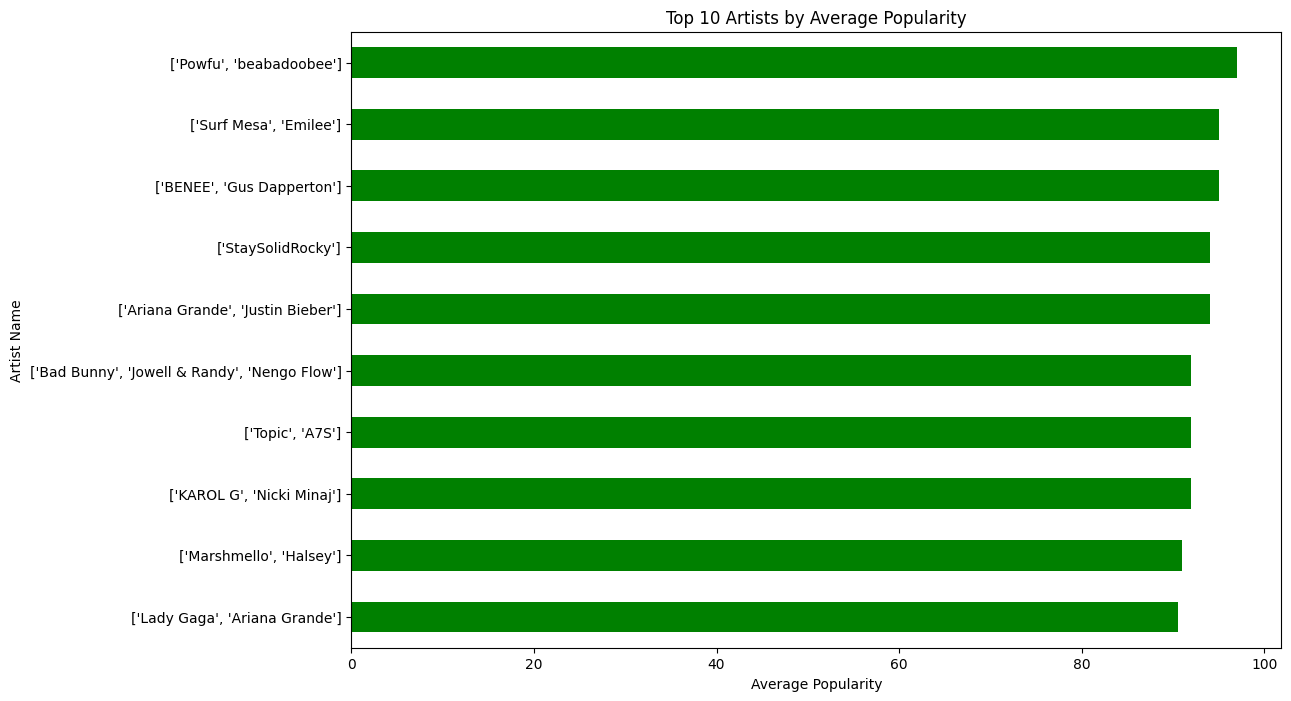

/tmp/ipykernel_13043/2460626021.py:23: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(data=df, x='Release_Date', y='Popularity', ci=None, color='orange')


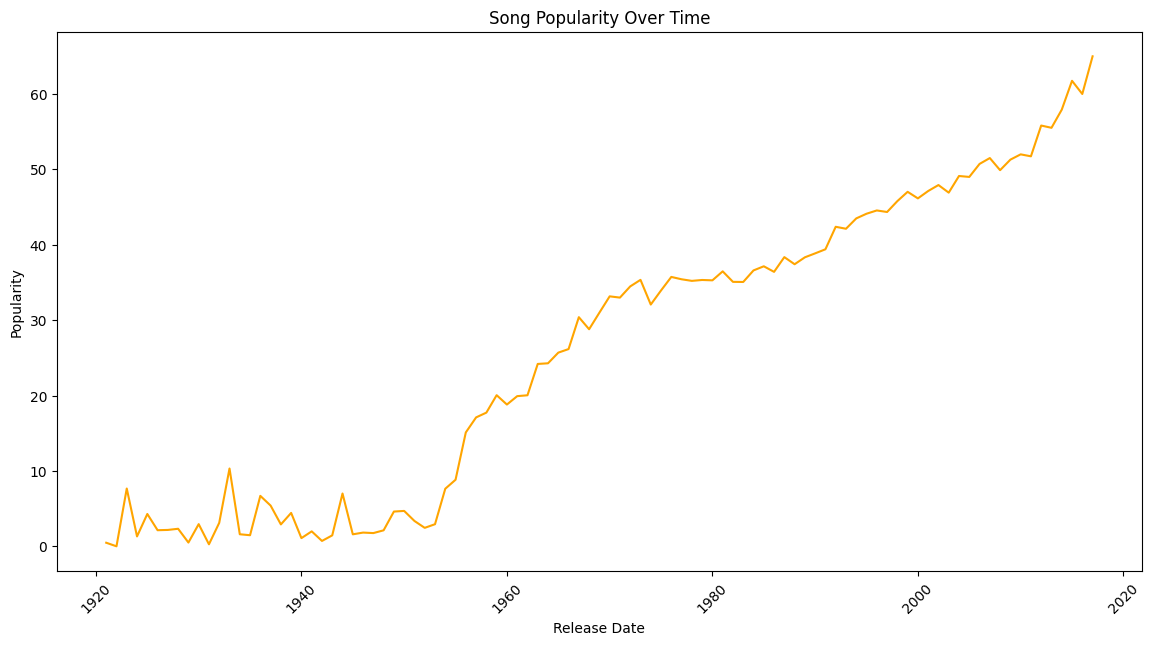

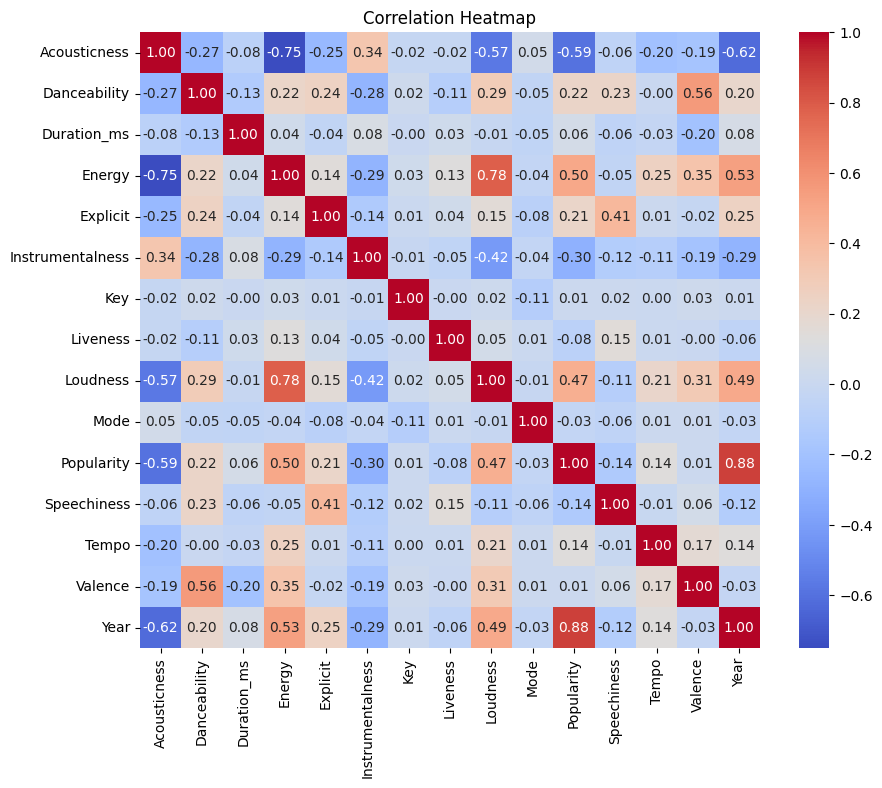

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Distribution of song popularity
plt.figure(figsize=(10, 6))
sns.histplot(df['Popularity'], kde=True, bins=30, color='blue')
plt.title('Distribution of Song Popularity')
plt.xlabel('Popularity')
plt.ylabel('Frequency')
plt.show()

# 2. Top-performing artists based on song popularity
top_artists = df.groupby('Artists')['Popularity'].mean().nlargest(10)
plt.figure(figsize=(12, 8))
top_artists.sort_values().plot(kind='barh', color='green')
plt.title('Top 10 Artists by Average Popularity')
plt.xlabel('Average Popularity')
plt.ylabel('Artist Name')
plt.show()

# 3. User engagement metrics over time
plt.figure(figsize=(14, 7))
sns.lineplot(data=df, x='Release_Date', y='Popularity', ci=None, color='orange')
plt.title('Song Popularity Over Time')
plt.xlabel('Release Date')
plt.ylabel('Popularity')
plt.xticks(rotation=45)
plt.show()

# 4. Correlation heatmap for numerical features
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=['number'])  # Select only numeric columns
correlation_matrix = numeric_df.corr()
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True)
plt.title('Correlation Heatmap')
plt.show()

# KPI Analysis

In this section, we will analyze the key performance indicators (KPIs) for the music streaming platform. The analysis will focus on:

1. Identifying the most popular songs and their characteristics.
2. Evaluating artist performance metrics.
3. Understanding user engagement trends and patterns.

In [21]:
# 1. Identifying the most popular songs and their characteristics
popular_songs = df.nlargest(10, 'Popularity')[['Track_Name', 'Artists', 'Popularity']]
print('Top 10 Most Popular Songs:')
print(popular_songs)

# 2. Evaluating artist performance metrics
artist_performance = df.groupby('Artists').agg({
    'Popularity': 'mean',
    'Track_Name': 'count'
}).rename(columns={'Track_Name': 'num_songs'}).sort_values(by='Popularity', ascending=False)
print('Artist Performance Metrics:')
print(artist_performance.head(10))

# 3. Understanding user engagement trends and patterns
engagement_trends = df.groupby('Release_Date').agg({
    'Popularity': 'mean'
}).reset_index()
print('User Engagement Trends:')
print(engagement_trends.head())

Top 10 Most Popular Songs:
                                              Track_Name  \
87942                                    Blinding Lights   
87940                       ROCKSTAR (feat. Roddy Ricch)   
87949  death bed (coffee for your head) (feat. beabad...   
87941                                         THE SCOTTS   
87840                                            The Box   
87844                                         Supalonely   
87852               ily (i love you baby) (feat. Emilee)   
87946                                       Toosie Slide   
87858                                       Dance Monkey   
87943                                         Party Girl   

                                          Artists  Popularity  
87942                              ['The Weeknd']         100  
87940                   ['DaBaby', 'Roddy Ricch']          99  
87949                    ['Powfu', 'beabadoobee']          97  
87941  ['THE SCOTTS', 'Travis Scott', 'Kid Cudi']       